# 18장 하이 로드 — 자기 조직화와 마르코프 담요 (실습)

1~17장은 「뇌는 자유 에너지를 줄인다」에서 출발했다(로우 로드). 이 장은 거꾸로 「무언가가 존재한다」에서 출발해 같은 결론에 닿는 길(하이 로드)을 수치로 따라간다.

1. 랑주뱅 동역학과 정상 분포 — 회전 흐름은 분포를 바꾸지 않는다
2. 놀람의 시간 평균은 엔트로피다
3. 회전 흐름에 대칭 성분이 섞이면
4. 마르코프 담요 — 정밀도 행렬의 0
5. 담요를 지키는 흐름, 깨는 흐름
6. 희소한 흐름은 담요를 보장하지 않는다
7. 내부 상태가 외부 상태를 「믿는가」 — 동기화 사상

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy.linalg import solve_continuous_lyapunov

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
np.set_printoptions(precision=3, suppress=True)

Sig = np.array([[1.0, 0.6], [0.6, 0.5]])      # 정상 분포 p(x) = N(0, Σ)
Pi = np.linalg.inv(Sig)                        # 정밀도. 놀람 −ln p(x) = ½ x'Πx + 상수
Gam = 0.5 * np.eye(2)                          # 확산 Γ (잡음 공분산 2Γ)
Lg = np.linalg.cholesky(Gam)
H_true = 0.5 * np.log((2 * np.pi * np.e) ** 2 * np.linalg.det(Sig))
print("Σ =\n", Sig, "\n엔트로피 H[p] =", round(H_true, 4))

Σ =
 [[1.  0.6]
 [0.6 0.5]] 
엔트로피 H[p] = 1.8548


## 1. 랑주뱅 동역학과 정상 분포

흐름 f(x) = −(Γ + Q)∇ℑ(x) 에 잡음을 더한 확률 미분 방정식을 푼다. Q 는 반대칭(Qᵀ = −Q)이다. 포커-플랑크 방정식에 따르면 Q 가 무엇이든 정상 분포는 p(x) 다. 입자 4000 개를 10 초 동안 움직여 마지막 분포의 공분산을 잰다.

In [2]:
def Qmat(q):
    return np.array([[0.0, q], [-q, 0.0]])

def ensemble(Q, N=4000, T=10.0, dt=0.002, seed=0):
    rng = np.random.default_rng(seed)
    x = np.zeros((N, 2)); J = -(Gam + Q) @ Pi
    for k in range(int(T / dt)):
        x = x + x @ J.T * dt + np.sqrt(2 * dt) * rng.standard_normal((N, 2)) @ Lg.T
    return x

def surprisal(x):
    return 0.5 * np.einsum("ij,jk,ik->i", x, Pi, x) + 0.5 * np.log((2 * np.pi) ** 2 * np.linalg.det(Sig))

for q in [0, 1, 3]:
    x = ensemble(Qmat(q))
    C = np.cov(x.T)
    print(f"q = {q}:  공분산 [{C[0,0]:.3f} {C[0,1]:.3f}; {C[1,1]:.3f}]   평균 놀람 {surprisal(x).mean():.3f}")

q = 0:  공분산 [0.999 0.604; 0.506]   평균 놀람 1.856


q = 1:  공분산 [1.012 0.611; 0.509]   평균 놀람 1.862


q = 3:  공분산 [1.001 0.604; 0.504]   평균 놀람 1.854


한 궤적을 그려 보면 차이가 보인다. q = 0 이면 흐름이 놀람의 기울기를 곧장 내려가므로 입자는 등고선을 가로질러 무작위로 오르내린다(상세 균형, 평형). q = 3 이면 등고선을 따라 도는 회전 흐름이 더해져 같은 분포를 돌면서 훑는다(비평형 정상 상태).

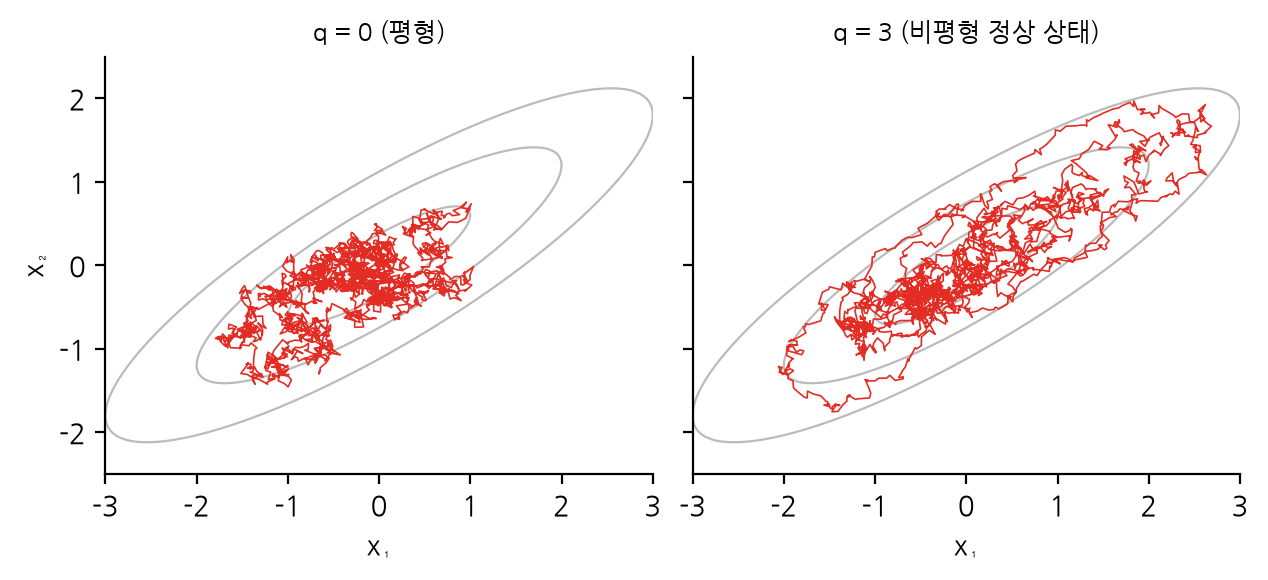

q = 0: 평균 순환 x₁·dx₂/dt − x₂·dx₁/dt =  -0.00,  자기 상관(0.5초) 0.781, (1초) 0.628
q = 3: 평균 순환 x₁·dx₂/dt − x₂·dx₁/dt =   6.17,  자기 상관(0.5초) -0.235, (1초) 0.043


In [3]:
def trajectory(Q, T=400.0, dt=0.002, seed=1):
    rng = np.random.default_rng(seed); n = int(T / dt)
    x = np.zeros((n, 2)); J = -(Gam + Q) @ Pi
    noise = np.sqrt(2 * dt) * rng.standard_normal((n, 2)) @ Lg.T
    for k in range(1, n):
        x[k] = x[k - 1] + J @ x[k - 1] * dt + noise[k]
    return x

g = np.linspace(-3, 3, 121); X, Y = np.meshgrid(g, g)
P = np.stack([X, Y], -1); Z = 0.5 * np.einsum("...i,ij,...j->...", P, Pi, P)
fig, ax = plt.subplots(1, 2, figsize=(6.4, 3.0), sharey=True)
trajs = {}
for a, q in zip(ax, [0, 3]):
    x = trajectory(Qmat(q)); trajs[q] = x
    a.contour(X, Y, Z, levels=[0.5, 2, 4.5], colors="#BBBBBB", linewidths=0.8)
    a.plot(x[:2500, 0], x[:2500, 1], color="#E32C24", lw=0.6)
    a.set_title(f"q = {q}" + (" (평형)" if q == 0 else " (비평형 정상 상태)"), fontsize=9)
    a.set_xlim(-3, 3); a.set_ylim(-2.5, 2.5); a.set_xlabel("x₁")
ax[0].set_ylabel("x₂")
plt.tight_layout(); plt.show()

for q, x in trajs.items():
    v = np.diff(x, axis=0) / 0.002
    circ = np.mean(x[:-1, 0] * v[:, 1] - x[:-1, 1] * v[:, 0])
    ac = [np.corrcoef(x[:-k, 0], x[k:, 0])[0, 1] for k in (250, 500)]
    print(f"q = {q}: 평균 순환 x₁·dx₂/dt − x₂·dx₁/dt = {circ:6.2f},  자기 상관(0.5초) {ac[0]:.3f}, (1초) {ac[1]:.3f}")

## 2. 놀람의 시간 평균은 엔트로피다

한 입자의 놀람을 시간에 걸쳐 평균하면 앙상블의 엔트로피 H[p] 에 수렴한다(에르고드성). 1.5 의 식을 수치로 확인한다.

q = 0: 400 초 놀람의 시간 평균 1.832  (엔트로피 1.855)
q = 3: 400 초 놀람의 시간 평균 1.886  (엔트로피 1.855)


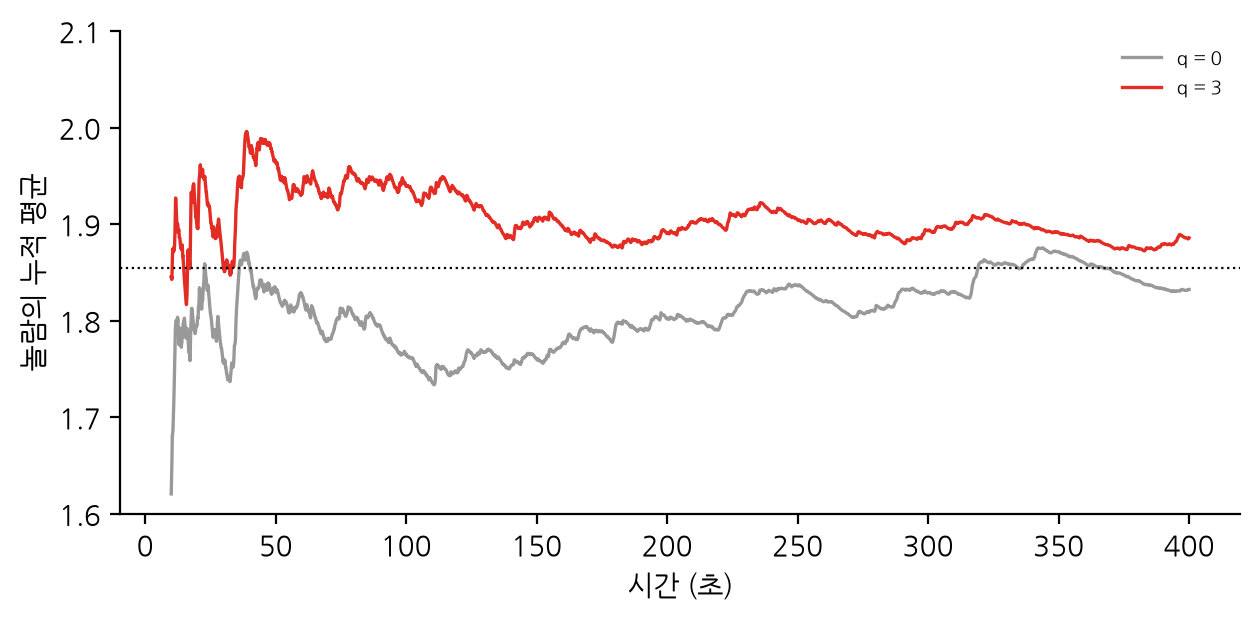

In [4]:
fig, ax = plt.subplots()
for q, c in [(0, "#999999"), (3, "#E32C24")]:
    x = trajs[q]
    s = surprisal(x)
    run = np.cumsum(s) / np.arange(1, len(s) + 1)
    t = np.arange(len(s)) * 0.002
    ax.plot(t[5000:], run[5000:], color=c, lw=1.2, label=f"q = {q}")
    print(f"q = {q}: 400 초 놀람의 시간 평균 {run[-1]:.3f}  (엔트로피 {H_true:.3f})")
ax.axhline(H_true, color="k", ls=":", lw=0.8); ax.set_ylim(1.6, 2.1)
ax.set_xlabel("시간 (초)"); ax.set_ylabel("놀람의 누적 평균")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 3. 실패 조건 — 회전 흐름에 대칭 성분이 섞이면

Q 가 반대칭이 아니면 「등고선을 따라 도는」 흐름이 아니게 된다. 대칭인 [[0, 1], [1, 0]] 을 넣으면 흐름의 야코비 행렬에 양의 고윳값이 생겨 계가 정상 분포를 잃고 발산한다.

In [5]:
for name, Q in [("반대칭 q = 1", Qmat(1)), ("대칭 성분", np.array([[0.0, 1.0], [1.0, 0.0]]))]:
    J = -(Gam + Q) @ Pi
    ev = np.linalg.eigvals(J)
    x = ensemble(Q, N=1000, T=3.0)
    print(f"{name:12s} 고윳값 {np.round(ev.real, 3)}   3 초 뒤 표준편차 {np.round(x.std(0), 2)}")

반대칭 q = 1    고윳값 [-2.679 -2.679]   3 초 뒤 표준편차 [1.  0.7]
대칭 성분        고윳값 [ 4.425 -1.211]   3 초 뒤 표준편차 [209280.31  80570.95]


## 4. 마르코프 담요

네 상태(외부 η, 감각 s, 능동 a, 내부 μ)의 정상 분포를 가우스로 둔다. 정밀도 행렬 Π 의 (η, μ) 원소가 0 이면 담요 b = (s, a) 가 주어졌을 때 η 와 μ 는 조건부 독립이다. 주변 상관은 0 이 아니어도 된다.

In [6]:
names = ["η", "s", "a", "μ"]
Pi4 = np.array([[ 2.0, -0.8,  0.0,  0.0],
                [-0.8,  2.0, -0.5, -0.6],
                [ 0.0, -0.5,  2.0, -0.7],
                [ 0.0, -0.6, -0.7,  2.0]])
Sig4 = np.linalg.inv(Pi4)
corr = Sig4[0, 3] / np.sqrt(Sig4[0, 0] * Sig4[3, 3])
pcorr = -Pi4[0, 3] / np.sqrt(Pi4[0, 0] * Pi4[3, 3])
print("Π =\n", Pi4)
print(f"η 와 μ 의 주변 상관 {corr:.3f},  담요가 주어졌을 때 편상관 {pcorr:.3f}")

# 표본으로 확인: b 로 회귀한 잔차끼리의 상관
rng = np.random.default_rng(SEED)
z = rng.multivariate_normal(np.zeros(4), Sig4, size=200000)
B = z[:, 1:3]
res = lambda y: y - B @ np.linalg.lstsq(B, y, rcond=None)[0]
print(f"표본: 주변 상관 {np.corrcoef(z[:, 0], z[:, 3])[0, 1]:.3f}, "
      f"담요로 회귀한 잔차의 상관 {np.corrcoef(res(z[:, 0]), res(z[:, 3]))[0, 1]:.4f}")

Π =
 [[ 2.  -0.8  0.   0. ]
 [-0.8  2.  -0.5 -0.6]
 [ 0.  -0.5  2.  -0.7]
 [ 0.  -0.6 -0.7  2. ]]
η 와 μ 의 주변 상관 0.214,  담요가 주어졌을 때 편상관 -0.000
표본: 주변 상관 0.210, 담요로 회귀한 잔차의 상관 -0.0033


## 5. 담요를 지키는 흐름, 깨는 흐름

정상 분포가 담요를 가져도 흐름 f = (Q − Γ)∇ℑ = (Q − Γ)Πx 가 η 와 μ 를 직접 잇는지는 Q 에 달렸다. 세 가지 Q 를 견준다. 셋 모두 정상 분포는 같다.

In [7]:
G4 = 0.5 * np.eye(4)
cases = {}
cases["Q = 0"] = np.zeros((4, 4))
Qb = np.zeros((4, 4)); Qb[1, 2], Qb[2, 1] = 1.0, -1.0; cases["Q 가 담요 안에서만"] = Qb
Qe = np.zeros((4, 4)); Qe[0, 1], Qe[1, 0] = 1.0, -1.0; cases["Q 가 η–s 를 잇는다"] = Qe
R = np.random.default_rng(0).normal(size=(4, 4)); cases["무작위 Q"] = R - R.T
for name, Q in cases.items():
    J = (Q - G4) @ Pi4
    S = solve_continuous_lyapunov(J, -2 * G4)
    print(f"{name:14s} ∂f_η/∂μ = {J[0, 3]:6.3f}   ∂f_μ/∂η = {J[3, 0]:6.3f}   정상 분포 유지: {np.allclose(S, Sig4)}")

Q = 0          ∂f_η/∂μ =  0.000   ∂f_μ/∂η =  0.000   정상 분포 유지: True
Q 가 담요 안에서만    ∂f_η/∂μ =  0.000   ∂f_μ/∂η =  0.000   정상 분포 유지: True
Q 가 η–s 를 잇는다  ∂f_η/∂μ = -0.600   ∂f_μ/∂η =  0.000   정상 분포 유지: True
무작위 Q          ∂f_η/∂μ =  3.677   ∂f_μ/∂η = -3.927   정상 분포 유지: True


## 6. 희소한 흐름은 담요를 보장하지 않는다

거꾸로 흐름에서 출발하자. η 와 μ 가 서로의 흐름에 직접 나타나지 않는(∂f_η/∂μ = ∂f_μ/∂η = 0) 안정한 선형계를 무작위로 2000 개 만들고, 정상 분포의 η–μ 편상관을 잰다.

|편상관| 중앙값 0.090,  0.01 미만 0.076,  0.05 미만 0.319


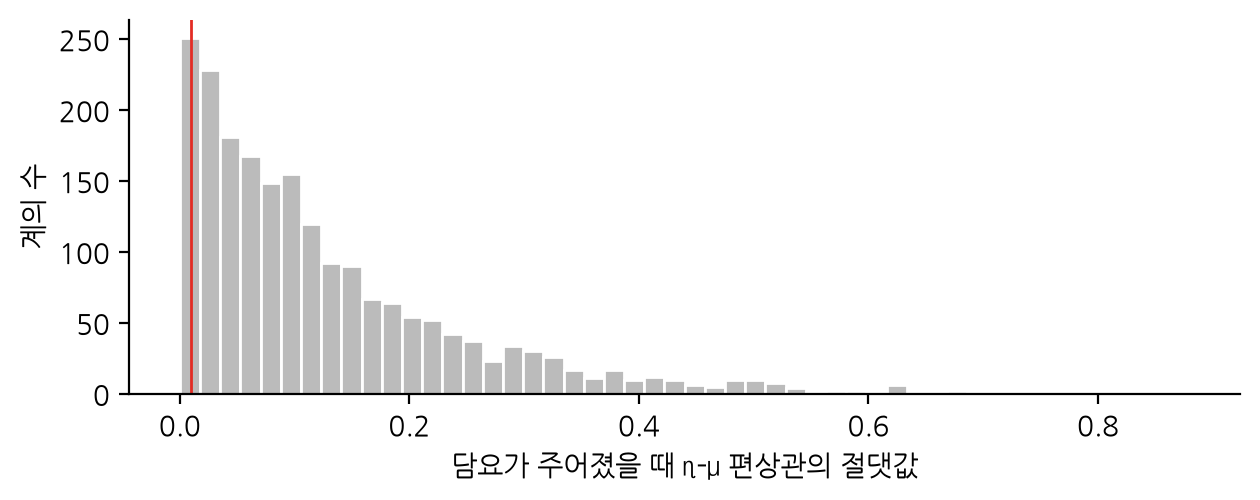

In [8]:
rng = np.random.default_rng(1)
pcs = []
for k in range(2000):
    J = rng.normal(size=(4, 4)); J[0, 3] = J[3, 0] = 0
    J -= np.eye(4) * (np.max(np.linalg.eigvals(J).real) + 0.5)   # 안정하게
    S = solve_continuous_lyapunov(J, -2 * G4); P = np.linalg.inv(S)
    pcs.append(abs(P[0, 3] / np.sqrt(P[0, 0] * P[3, 3])))
pcs = np.array(pcs)
print(f"|편상관| 중앙값 {np.median(pcs):.3f},  0.01 미만 {np.mean(pcs < 0.01):.3f},  0.05 미만 {np.mean(pcs < 0.05):.3f}")
fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.hist(pcs, bins=50, color="#BBBBBB", edgecolor="white")
ax.axvline(0.01, color="#E32C24", lw=1)
ax.set_xlabel("담요가 주어졌을 때 η–μ 편상관의 절댓값"); ax.set_ylabel("계의 수")
plt.tight_layout(); plt.show()

## 7. 동기화 사상

담요 b 가 주어졌을 때 내부 상태의 기댓값 E[μ|b] 와 외부 상태의 기댓값 E[η|b] 는 모두 b 의 일차 함수다. 내부 상태가 외부 상태에 대한 믿음을 「부호화」한다는 말은 E[μ|b] 에서 E[η|b] 로 가는 함수(동기화 사상)가 있다는 뜻이다. 두 계수 벡터가 평행할 때만 그런 함수가 있다.

In [9]:
def sync_r2(P):
    b = [1, 2]
    w_eta = -P[0, b] / P[0, 0]          # E[η|b] = w_eta · b
    w_mu = -P[3, b] / P[3, 3]           # E[μ|b] = w_mu · b
    Sb = np.linalg.inv(P)[np.ix_(b, b)]  # 담요의 주변 공분산
    rng = np.random.default_rng(SEED)
    bs = rng.multivariate_normal(np.zeros(2), Sb, size=50000)
    e, m = bs @ w_eta, bs @ w_mu
    r2 = np.corrcoef(e, m)[0, 1] ** 2
    return w_eta, w_mu, r2

for name, P in [("앞의 Π", Pi4), ("η 와 μ 가 담요를 같은 비율로 보는 Π", None)]:
    if P is None:
        P = Pi4.copy(); P[0, 2] = P[2, 0] = -0.8 * 0.7 / 0.6    # η 의 (s, a) 결합을 μ 와 평행하게
    w_e, w_m, r2 = sync_r2(P)
    print(f"{name}: Π 의 최소 고윳값 {np.linalg.eigvalsh(P).min():.3f}")
    print(f"  E[η|b] 계수 {np.round(w_e, 3) + 0.0}, E[μ|b] 계수 {np.round(w_m, 3) + 0.0}, "
          f"μ 로 η 를 맞히는 R² = {r2:.3f}")

앞의 Π: Π 의 최소 고윳값 0.629
  E[η|b] 계수 [0.4 0. ], E[μ|b] 계수 [0.3  0.35], μ 로 η 를 맞히는 R² = 0.698
η 와 μ 가 담요를 같은 비율로 보는 Π: Π 의 최소 고윳값 0.195
  E[η|b] 계수 [0.4   0.467], E[μ|b] 계수 [0.3  0.35], μ 로 η 를 맞히는 R² = 1.000
